<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 11: CNN for Image Classification
Google Colab-ready code — uses CIFAR-10 as the substitute dataset. Run the following cells in order.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.7458 - loss: 0.9324 - val_accuracy: 0.8810 - val_loss: 0.3794
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.9140 - loss: 0.2952 - val_accuracy: 0.9110 - val_loss: 0.2971
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9355 - loss: 0.2173 - val_accuracy: 0.9210 - val_loss: 0.2626
Test Accuracy: 91.1 %


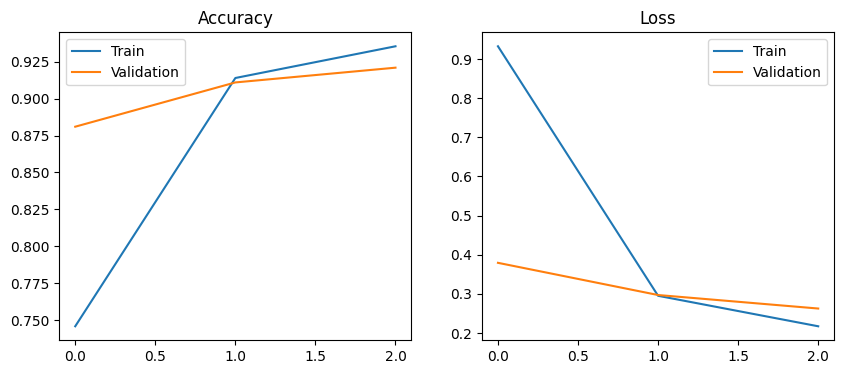

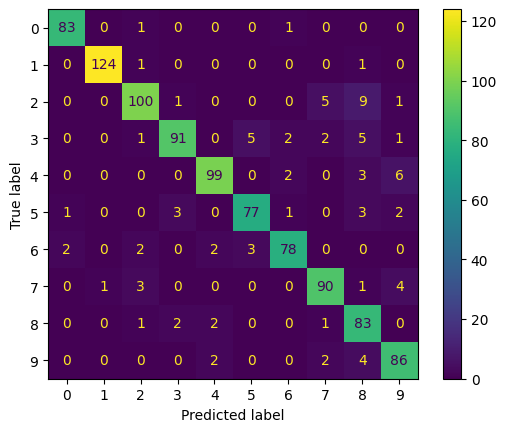

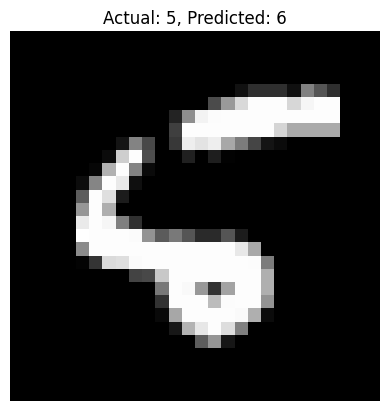

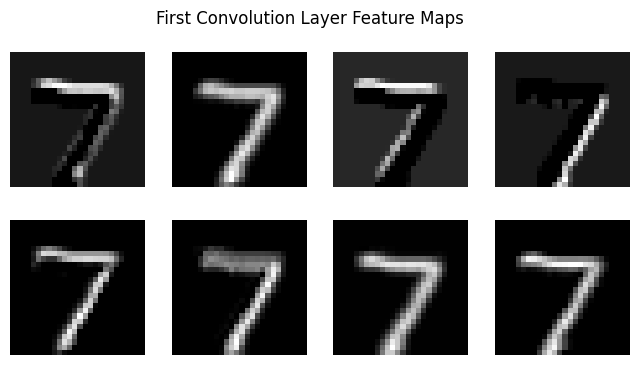

In [2]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load small MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Use fewer images for faster training
x_train = x_train[:5000] / 255.0
y_train = y_train[:5000]
x_test = x_test[:1000] / 255.0
y_test = y_test[:1000]

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Build CNN
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train model with validation split
history = model.fit(x_train, y_train, epochs=3,
                    validation_split=0.2, verbose=1)

# Test accuracy
loss, acc = model.evaluate(x_test, y_test, verbose=0)
print("Test Accuracy:", round(acc * 100, 2), "%")

# Accuracy and loss graphs
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.legend()
plt.show()

# Confusion matrix
pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot()
plt.show()

# Sample misclassified image
wrong = np.where(pred != y_test)[0]
if len(wrong) > 0:
    i = wrong[0]
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    plt.title(f"Actual: {y_test[i]}, Predicted: {pred[i]}")
    plt.axis('off')
    plt.show()

# First convolution layer feature maps
feature_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.layers[0].output
)
features = feature_model.predict(x_test[:1], verbose=0)

plt.figure(figsize=(8, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(features[0, :, :, i], cmap='gray')
    plt.axis('off')
plt.suptitle('First Convolution Layer Feature Maps')
plt.show()
